# ESPRI ADC：独立模拟样本评估

**功能**：加载 `ADC_output/EspriADC_Left.pt`、`EspriADC_Right.pt`，预测独立预处理模拟数据的顶点质子动能。
**方法**：使用模型保存的逐棒标定将 ENaI 反算为连续 ADC；四输入 `[ADC, rdcX, rdcY, NaIID]`，
CPU float64、训练集归一化、eval/no_grad 分批预测；不训练、不重新拟合归一化。
**注意事项**：先运行 `EspriADC.ipynb` 保存模型。输入为上级 InputRootFiles 的独立 Eval 树，
一行一个事件；不重跑 PreProcess.C。输入与训练文件路径或文件内容相同时报错（无法识别重新生成的部分重复事件）。
保留全部输入行序，基础无效输入写 -999 并置 InputOK/PredictionOK=0；棒号与 ADC 反算异常直接报错。
ETrue 可选；只对有效预测和有限正真值评价，绘图范围不删除统计样本。
固定输出 `Eval/`，重新运行覆盖同名结果。逐事件输出 ROOT/CSV、独立 Eval 统计 JSON 和全部四输入诊断 PDF/PNG。
Train/Test 五项指标由训练 Notebook 给出；本 Notebook 的 Eval 不冒充训练集或内部 Test。
实现参考 nndl-practice/pytorch/nndl/runner.py 的 eval/no_grad 模式；沿用本项目 Notebook 的模型接口。


In [1]:
# 功能：配置独立 ADC 模型评估；输出仅在本文件夹 Eval 内。
# 方法：uproot/awkward → NumPy float64 → checkpoint 反算 ADC → 保存的完整模型推理。
# 注意事项：先生成独立 Eval 树与固定目录内模型；不运行训练和预处理宏。
from pathlib import Path
import hashlib
import json
import numpy as np
import awkward as ak
import uproot
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Math
DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
device = torch.device("cpu")
PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
WORK_DIR = PROJECT_DIR / "ADCToProtonEnergy"
MODEL_DIR = WORK_DIR / "ADC_output"
FEATURE_NAMES = ["ADC", "rdcX", "rdcY", "NaIID"]
FEATURE_UNITS = ["channel", "mm", "mm", "1"]
INVALID_VALUE = -999.0
PREDICT_BATCH_SIZE = 4096
RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV = -10.0, 10.0
RESIDUAL_HIST_BIN_WIDTH_MEV = 0.2
plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0})

EVALUATION_FILES = {
    "Left": PROJECT_DIR / "InputRootFiles/Processed_Left_Eval.root",
    "Right": PROJECT_DIR / "InputRootFiles/Processed_Right_Eval.root",
}
TREE_NAME = "tree"
OUTPUT_DIR = WORK_DIR / "Eval"
OUTPUT_DIR.mkdir(exist_ok=True)
display(Math(r"Q=\frac{E_{\mathrm{NaI}}-C}{A-B(E_{\mathrm{NaI}}-C)},\quad \widehat E=f_\theta(Q,\mathrm{rdcX},\mathrm{rdcY},\mathrm{NaIID})"))


<IPython.core.display.Math object>

In [2]:
# 功能：校验 ADC 模型、预处理及逐棒标定，并提供只读的分批推理。
# 方法：加载可信完整模型，复用训练集 float64 归一化和 checkpoint 内的标定快照。
# 注意事项：只接受本项目四输入/对应臂；不重新训练、不重新拟合归一化。
def load_adc_model(arm):
    path = MODEL_DIR / f"EspriADC_{arm}.pt"
    saved = torch.load(path, map_location="cpu", weights_only=False)
    if (saved["arm"] != arm or list(saved["feature_names"]) != FEATURE_NAMES
            or list(saved["feature_units"]) != FEATURE_UNITS
            or saved["target_name"] != "ETrue" or saved["target_unit"] != "MeV"):
        raise ValueError(f"{arm} 模型臂、特征顺序、单位或目标不匹配。")
    config = saved["configuration"]
    expected_map = {"Left": {"side": 1, "id_min": 1}, "Right": {"side": 0, "id_min": 8}}
    if (config.get("dtype") != "float64" or config.get("arm_calibration_mapping") != expected_map
            or config.get("adc_formula") != "Q=(ENaI-C)/(A-B*(ENaI-C))"
            or config.get("adc_quantized") is not False or config.get("adc_added_noise") is not False):
        raise ValueError("模型的 ADC 定义、精度或编号映射不匹配。")
    raw = config["calibration_text"].encode("utf-8")
    if hashlib.sha256(raw).hexdigest() != config["calibration_sha256"]:
        raise ValueError("模型内标定原文与 SHA256 不一致。")
    table = np.loadtxt(raw.decode("utf-8").splitlines(), ndmin=2, dtype=np.float64)
    if table.shape != (14, 5) or not np.isfinite(table).all() or not np.array_equal(table, np.asarray(config["calibration_table"])):
        raise ValueError("模型内标定表异常。")
    keys = table[:, :2]
    if (set(map(tuple, keys)) != {(s,b) for s in (0,1) for b in range(7)}
            or np.any(table[:, 2] <= 0)):
        raise ValueError("标定键或 A 系数异常。")
    for key, shape in [("x_mean", (4,)), ("x_std", (4,)), ("y_mean", (1,)), ("y_std", (1,)),
                       ("train_feature_min", (4,)), ("train_feature_max", (4,))]:
        value = np.asarray(saved[key], dtype=np.float64)
        if value.shape != shape or not np.isfinite(value).all():
            raise ValueError(f"归一化/范围参数 {key} 异常。")
        saved[key] = value
    if np.any(saved["x_std"] <= 0) or np.any(saved["y_std"] <= 0):
        raise ValueError("模型归一化缩放必须为正。")
    model = saved["model"]
    parameters = list(model.parameters())
    linear = [layer for layer in model.modules() if isinstance(layer, torch.nn.Linear)]
    if (not linear or linear[0].in_features != 4 or linear[-1].out_features != 1
            or any(p.dtype != torch.float64 for p in parameters)):
        raise ValueError("实际网络维度或精度不匹配。")
    saved["model"] = model.to(device=device, dtype=DTYPE).eval()
    saved["checkpoint_path"] = str(path.resolve())
    saved["checkpoint_sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    return saved


def predict_saved(saved, X):
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2 or X.shape[1] != 4 or not np.isfinite(X).all():
        raise ValueError("推理输入应为有限 N×4 数组。")
    rule = saved["configuration"]["arm_calibration_mapping"][saved["arm"]]
    ids = X[:, 3]
    if (np.any(X[:, 0] < 0) or np.any(ids != np.floor(ids))
            or np.any(ids < rule["id_min"]) or np.any(ids > rule["id_min"] + 6)):
        raise ValueError("ADC 或 NaIID 非物理/臂不匹配。")
    prediction = np.empty(len(X), dtype=np.float64)
    model = saved["model"]
    model.eval()
    for first in range(0, len(X), PREDICT_BATCH_SIZE):
        stop = min(first + PREDICT_BATCH_SIZE, len(X))
        scaled = (X[first:stop] - saved["x_mean"]) / saved["x_std"]
        tensor = torch.from_numpy(np.ascontiguousarray(scaled)).to(device=device, dtype=DTYPE)
        with torch.no_grad():
            values = model(tensor).cpu().numpy()
        if values.shape != (stop-first, 1):
            raise ValueError("模型输出形状不是 (N,1)。")
        prediction[first:stop] = (values * saved["y_std"] + saved["y_mean"]).reshape(-1)
    if not np.isfinite(prediction).all():
        raise ValueError("预测出现 NaN/Inf，停止输出。")
    return prediction


def coefficients_for_ids(saved, ids):
    rule = saved["configuration"]["arm_calibration_mapping"][saved["arm"]]
    if (not np.isfinite(ids).all() or np.any(ids != np.floor(ids))
            or np.any(ids < rule["id_min"]) or np.any(ids > rule["id_min"] + 6)):
        raise ValueError(f"{saved['arm']} NaIID 必须为对应臂的合法整数。")
    table = np.asarray(saved["configuration"]["calibration_table"], dtype=np.float64)
    lookup = {(int(s),int(b)): row for s,b,*row in table}
    return np.asarray([lookup[(rule["side"],int(i)-rule["id_min"])] for i in ids],dtype=np.float64).reshape(-1,3)

def read_features(path, tree_name, feature_names, target_name="ETrue"):
    """读取标量预处理树；保留全部行，标签可以不存在。"""
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"ROOT 文件不存在：{path}")
    with uproot.open(path) as root_file:
        tree = root_file[tree_name]
        missing = [name for name in feature_names if name not in tree.keys()]
        if missing:
            raise ValueError(f"{path.name}/{tree_name} 缺少输入分支：{missing}")
        has_target = target_name in tree.keys()
        names = list(feature_names) + ([target_name] if has_target else [])
        arrays = tree.arrays(names, library="ak", how=dict)
        columns = [np.asarray(ak.to_numpy(arrays[name]), dtype=np.float64) for name in names]
        if any(column.ndim != 1 for column in columns):
            raise ValueError("需要每个事件一行的标量分支，不接受未预处理的多命中数组。")
        if len({len(column) for column in columns}) != 1:
            raise ValueError("输入与标签的行数不一致。")
        X = np.column_stack(columns[:len(feature_names)]).astype(np.float64)
        y = columns[-1].reshape(-1, 1) if has_target else None
    return X, y

def valid_features(X):
    # 不新增角度或坐标接受度门；预处理已经负责物理筛选。
    finite = np.isfinite(X).all(axis=1)
    return finite & (X[:, 0] > 0.0) & (X != INVALID_VALUE).all(axis=1)

def load_calibration(path):
    """严格读取 side, bar, A, B, C 共 14 行，保留原文件内容用于追溯。"""
    raw = path.read_bytes()
    table = np.loadtxt(raw.decode("utf-8").splitlines(), dtype=np.float64, ndmin=2)
    if table.shape != (14, 5) or not np.isfinite(table).all():
        raise ValueError("标定表应为 14×5 个有限数值：side, bar, A, B, C。")
    mapping = {}
    for side, bar, a, b, c in table:
        if side not in (0, 1) or bar != np.floor(bar) or not 0 <= bar <= 6 or a <= 0:
            raise ValueError(f"标定表含非法行：{side, bar, a, b, c}")
        key = (int(side), int(bar))
        if key in mapping:
            raise ValueError(f"重复标定键：{key}")
        mapping[key] = np.array([a, b, c], dtype=np.float64)
    if set(mapping) != {(s, b) for s in (0, 1) for b in range(7)}:
        raise ValueError("标定表缺失 side/bar。")
    return mapping, table, raw

def energy_to_adc(energy, coefficients, source_rows, arm):
    """连续反演并验证原公式的物理解；不取整、裁剪或添加噪声。"""
    a, b, c = coefficients.T
    delta = energy - c
    denominator = a - b * delta
    ok = np.isfinite(delta) & (delta >= 0.0) & np.isfinite(denominator) & (denominator > 0.0)
    if not ok.all():
        bad = np.flatnonzero(~ok)[:10]
        raise ValueError(f"{arm} ADC 反算无物理解；SourceEntry={source_rows[bad].tolist()}, "
                         f"ENaI={energy[bad].tolist()}, denominator={denominator[bad].tolist()}")
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        adc = delta / denominator
        forward_denominator = 1.0 + b * adc
        recovered = a * adc / forward_denominator + c
    ok = (np.isfinite(adc) & (adc >= 0.0) & np.isfinite(forward_denominator)
          & (forward_denominator > 0.0) & np.isfinite(recovered)
          & np.isclose(recovered, energy, rtol=1e-10, atol=1e-10))
    if not ok.all():
        raise ValueError(f"{arm} ADC/回代异常；SourceEntry={source_rows[~ok][:10].tolist()}")
    return adc

def finish_figure(fig, axes, path):
    """统一绘图区比例，隐藏横轴首尾可见刻度文字，并紧凑导出。"""
    axes = np.asarray(axes, dtype=object).reshape(-1)
    for ax in axes:
        ax.set_box_aspect(3.0 / 4.0)
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True)
    fig.canvas.draw()
    for ax in axes:
        low, high = sorted(ax.get_xlim())
        labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
                  if low <= tick.get_loc() <= high and tick.label1.get_visible()]
        if len(labels) > 1:
            labels[0].set_visible(False)
            labels[-1].set_visible(False)
    fig.savefig(path, bbox_inches="tight", pad_inches=0.06)
    fig.savefig(path.with_suffix(".png"), dpi=180, bbox_inches="tight", pad_inches=0.06)
    plt.show()
    plt.close(fig)

def regression_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64).reshape(-1)
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    if truth.shape != prediction.shape:
        raise ValueError("真值与预测的事件数不一致。")
    if not np.isfinite(truth).all() or not np.isfinite(prediction).all():
        raise ValueError("真值或预测包含 NaN/Inf，不能静默删除后统计。")
    residual = prediction - truth
    if len(residual) == 0:
        raise ValueError("没有可用于计算误差的有效真值。")
    mse = float(np.mean(residual**2))
    total = float(np.sum((truth - truth.mean())**2))
    q16, q50, q84 = np.quantile(residual, [0.16, 0.50, 0.84])
    core = residual[(residual >= q16) & (residual <= q84)]
    if core.size == 0:
        raise ValueError("Q16–Q84 区间内没有事件，无法计算 RMS_68。")
    return {
        "n": int(len(residual)), "mse_MeV2": mse,
        "rmse_MeV": float(np.sqrt(mse)), "mae_MeV": float(np.mean(np.abs(residual))),
        "r2": float(1.0 - np.sum(residual**2) / total) if total > 0.0 else None,
        "bias_MeV": float(residual.mean()),
        "residual_std_MeV": float(residual.std(ddof=1)) if len(residual) > 1 else 0.0,
        "residual_q16_MeV": float(q16), "residual_median_MeV": float(q50),
        "residual_q84_MeV": float(q84), "central68_half_width_MeV": float((q84 - q16) / 2.0),
        "truncated_rms68_MeV": float(np.sqrt(np.mean(core**2))),
    }

def print_regression_metrics(arm, subset, metrics):
    """保留左侧标签的自然间距，只在冒号后补空格，使五项数值小数点对齐。"""
    import unicodedata

    rows = [
        ("平均绝对误差 (Mean Absolute Error, MAE):", metrics["mae_MeV"]),
        ("平均偏差 (Mean Bias, Bias):", metrics["bias_MeV"]),
        ("均方根误差 (Root Mean Square Error, RMSE):", metrics["rmse_MeV"]),
        ("截尾均方根 (Truncated RMS, RMS_68):", metrics["truncated_rms68_MeV"]),
        ("中心68%半宽 (Central 68% Half Width, W_68):", metrics["central68_half_width_MeV"]),
    ]

    def display_width(text):
        return sum(0 if unicodedata.combining(char) else
                   2 if unicodedata.east_asian_width(char) in ("W", "F") else 1
                   for char in text)

    label_width = max(display_width(label) for label, _ in rows)
    values = [f"{value:.6f}" for _, value in rows]
    value_width = max(14, max(len(value) for value in values))
    print(f"\n{arm} {subset}（完整评估样本数：{metrics['n']}）", flush=True)
    for (label, _), value in zip(rows, values):
        padding = label_width - display_width(label) + 1 + value_width - len(value)
        print(f"{label}{' ' * padding}{value} MeV", flush=True)

def plot_diagnostics(arm, X, truth, prediction, path, sample_label):
    """所有宽度均为样本统计量，不进行高斯拟合。"""
    truth = np.asarray(truth).reshape(-1)
    prediction = np.asarray(prediction).reshape(-1)
    residual = prediction - truth
    fig, axes = plt.subplots(3, 3, figsize=(13.5, 10.8), layout="constrained")
    panels = axes.ravel()
    ax = axes[0, 0]
    ax.scatter(truth, prediction, s=7, color="black", alpha=0.35, linewidths=0)
    bounds = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    ax.plot(bounds, bounds, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="True proton energy (MeV)", ylabel="Predicted proton energy (MeV)")
    ax = axes[0, 1]
    # 固定 100 个箱；只改变显示，不用这个窗口筛选误差指标。
    bin_count = int(round((RESIDUAL_HIST_MAX_MEV - RESIDUAL_HIST_MIN_MEV) / RESIDUAL_HIST_BIN_WIDTH_MEV))
    histogram_edges = np.linspace(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV, bin_count + 1)
    counts, edges, _ = ax.hist(residual, bins=histogram_edges, histtype="step", color="blue", linewidth=1)
    ax.set_xlim(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV)
    print(f"{arm} {sample_label}: residual histogram below range={(residual < RESIDUAL_HIST_MIN_MEV).sum()}, "
          f"above range={(residual > RESIDUAL_HIST_MAX_MEV).sum()}; metrics use all {len(residual)} events")
    ax.set_ylim(0.0, max(1.0, 1.18 * counts.max()))
    ax.set(xlabel="Predicted - true energy (MeV)", ylabel=f"Counts / {edges[1] - edges[0]:.3g} MeV")
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
    xs = [truth, *X.T]
    labels = ["True proton energy (MeV)", "ADC (channel)", "rdcX (mm)", "rdcY (mm)", "NaIID (dimensionless)"]
    residual_limit = max(1e-6, 1.08 * np.max(np.abs(residual)))
    for ax, values, label in zip(panels[2:7], xs, labels):
        ax.scatter(values, residual, s=7, color="black", alpha=0.35, linewidths=0)
        ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
        ax.set(xlabel=label, ylabel="Predicted - true energy (MeV)")
        ax.set_ylim(-residual_limit, residual_limit)
    for ax in panels[7:]:
        fig.delaxes(ax)
    finish_figure(fig, panels[:7], path)


## 读取、预测及保留逐事件输出
标定使用模型内快照，不重新读取可能已更新的外部标定表。超出训练单列范围仅标记。


In [3]:
results, summary = {}, {}
for arm, path in EVALUATION_FILES.items():
    if path is None:
        continue
    path = Path(path).resolve()
    saved = load_adc_model(arm)
    input_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    if path == Path(saved["input_path"]).resolve() or input_hash == saved["input_sha256"]:
        raise ValueError(f"{arm} 独立样本与训练来源相同。")
    raw_X, truth = read_features(path, TREE_NAME, ["ENaI", "RDCX", "RDCY", "NaIBarID"])
    coeff = coefficients_for_ids(saved, raw_X[:, 3])
    input_ok = valid_features(raw_X[:, :3])
    rows = np.flatnonzero(input_ok)
    X = np.column_stack((np.full(len(raw_X), INVALID_VALUE), raw_X[:, 1:]))
    X[rows, 0] = energy_to_adc(raw_X[rows, 0], coeff[rows], rows, arm)
    prediction = np.full(len(X), INVALID_VALUE, dtype=np.float64)
    prediction[rows] = predict_saved(saved, X[rows])
    outside = np.zeros(len(X), dtype=np.int8)
    outside[rows] = ((X[rows] < saved["train_feature_min"]) |
                     (X[rows] > saved["train_feature_max"])).any(axis=1).astype(np.int8)
    output = {"SourceEntry": np.arange(len(X), dtype=np.int64), "ENaI": raw_X[:, 0],
              **{name: X[:, i] for i, name in enumerate(FEATURE_NAMES)},
              "EPred": prediction, "InputOK": input_ok.astype(np.int8),
              "PredictionOK": input_ok.astype(np.int8), "OutsideTrainingRange": outside}
    mask = np.zeros(len(X), dtype=bool)
    metrics = None
    if truth is not None:
        mask = input_ok & np.isfinite(truth[:, 0]) & (truth[:, 0] > 0.0)
        residual = np.full(len(X), INVALID_VALUE)
        residual[mask] = prediction[mask] - truth[mask, 0]
        output.update(ETrue=truth[:, 0], TruthOK=mask.astype(np.int8), Residual=residual)
        if mask.any():
            metrics = regression_metrics(truth[mask, 0], prediction[mask])
    with uproot.recreate(OUTPUT_DIR / f"Pred_{arm}.root") as root_file:
        outtree = root_file.mktree("tree", {key: value.dtype for key, value in output.items()})
        outtree.extend(output)
    np.savetxt(OUTPUT_DIR / f"Pred_{arm}.csv", np.column_stack(list(output.values())),
               delimiter=",", header=",".join(output), comments="", fmt="%.17g")
    summary[arm] = {"input_path": str(path), "input_sha256": input_hash,
                    "checkpoint": saved["checkpoint_path"], "checkpoint_sha256": saved["checkpoint_sha256"],
                    "calibration_sha256": saved["configuration"]["calibration_sha256"],
                    "configuration": saved["configuration"], "entries": len(X),
                    "valid_predictions": int(input_ok.sum()), "invalid_inputs": int((~input_ok).sum()),
                    "outside_training_range": int(outside.sum()), "metrics": metrics}
    results[arm] = {"X": X, "truth": truth, "prediction": prediction, "mask": mask, "metrics": metrics}
    print(f"{arm}: entries={len(X)}, invalid inputs={(~input_ok).sum()}, valid predictions={len(rows)}, valid truth={mask.sum()}")
(OUTPUT_DIR / "evaluation.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")


Left: entries=12038, invalid inputs=0, valid predictions=12038, valid truth=12038
Right: entries=11792, invalid inputs=0, valid predictions=11792, valid truth=11792


9796

## 独立 Eval 诊断与完整有效样本统计
残差为预测减真值，所有四个输入均有残差关联图；图后统一打印五项指标。


Left independent Eval: residual histogram below range=34, above range=0; metrics use all 12038 events


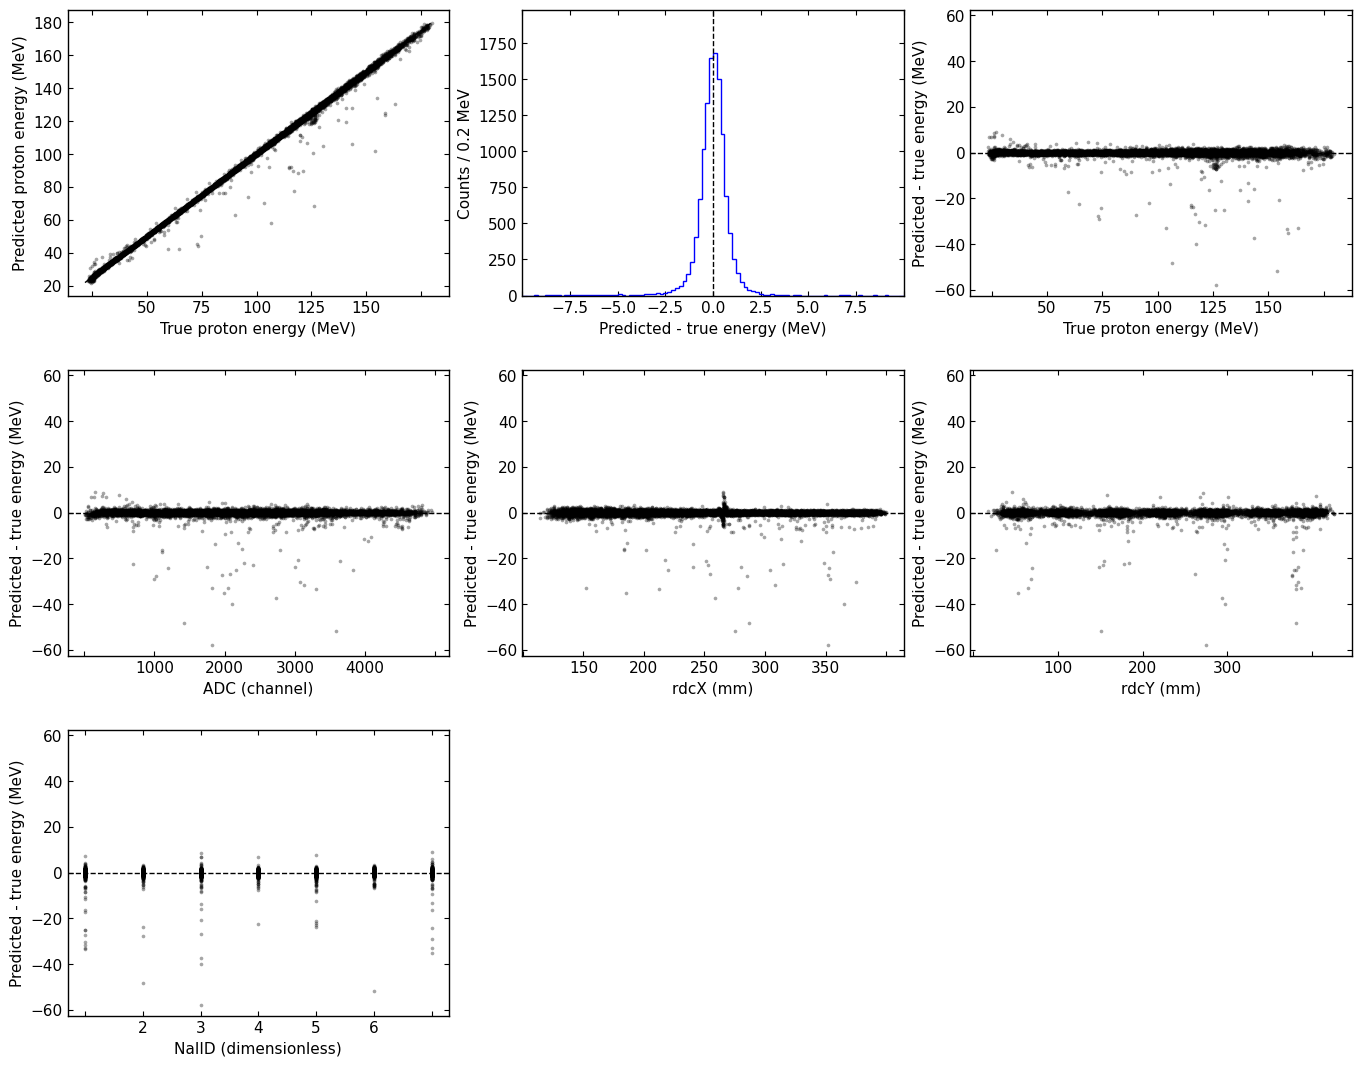

Right independent Eval: residual histogram below range=42, above range=2; metrics use all 11792 events


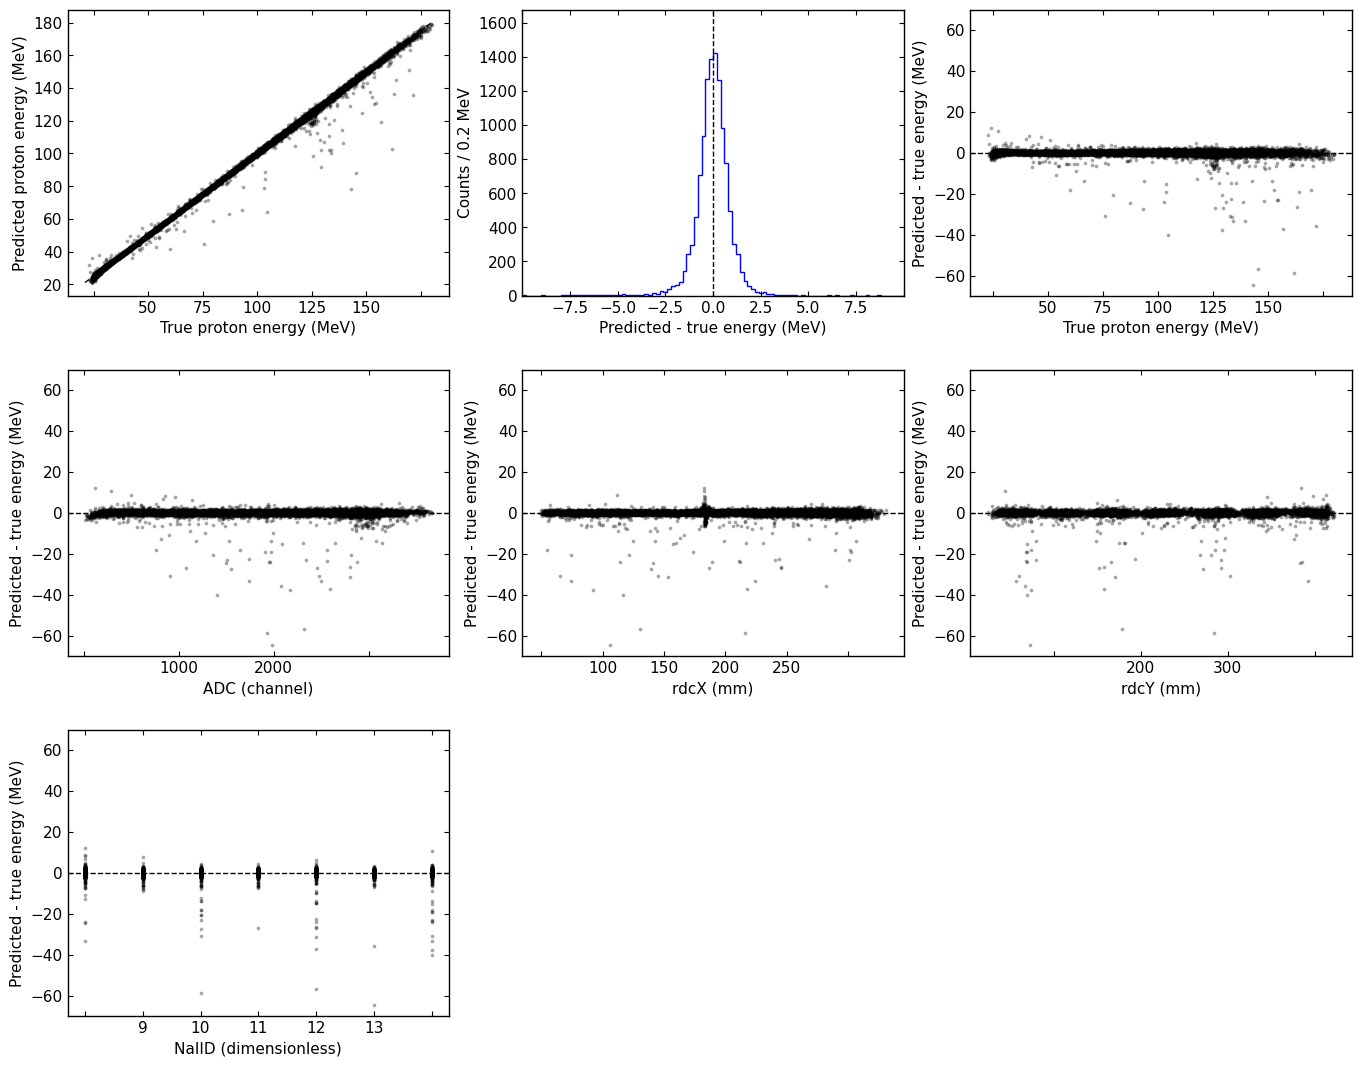


Left Independent Eval（完整评估样本数：12038）
平均绝对误差 (Mean Absolute Error, MAE):          0.619782 MeV
平均偏差 (Mean Bias, Bias):                      -0.099761 MeV
均方根误差 (Root Mean Square Error, RMSE):        1.754026 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.309532 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.587299 MeV

Right Independent Eval（完整评估样本数：11792）
平均绝对误差 (Mean Absolute Error, MAE):          0.718445 MeV
平均偏差 (Mean Bias, Bias):                      -0.128325 MeV
均方根误差 (Root Mean Square Error, RMSE):        1.947852 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.364092 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.693515 MeV
零偏差理想高斯：RMSE=σ，RMS_68≈0.54σ，W_68≈0.994σ；不能仅凭比值判断高斯性。


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
for arm, result in results.items():
    if result["metrics"] is None:
        print(f"{arm}: 无有效真值，跳过诊断。")
        continue
    mask = result["mask"]
    plot_diagnostics(arm, result["X"][mask], result["truth"][mask, 0], result["prediction"][mask],
                     OUTPUT_DIR / f"Diag_{arm}.pdf", "independent Eval")
for arm, result in results.items():
    if result["metrics"] is not None:
        print_regression_metrics(arm, "Independent Eval", result["metrics"])
print("零偏差理想高斯：RMSE=σ，RMS_68≈0.54σ，W_68≈0.994σ；不能仅凭比值判断高斯性。")
display(Math(r"r=\widehat E-E,\quad \mathrm{MAE}=\langle|r|\rangle,\quad \mathrm{Bias}=\langle r\rangle,\quad \mathrm{RMSE}=\sqrt{\langle r^2\rangle}"))
display(Math(r"\mathrm{RMS}_{68}=\sqrt{\langle r^2\rangle_{Q_{16}\le r\le Q_{84}}},\quad W_{68}=(Q_{84}-Q_{16})/2"))
